In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import SGDRegressor
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_squared_error

df = pd.read_csv('/kaggle/input/datasets/yazanpc/houses/housing.csv')
df = df.dropna()
df_filtered = df[(df['median_income'] > 1) & (df['median_income'] < 6)]

X = df_filtered[['median_income']].values[:200]
y = df_filtered['median_house_value'].values[:200]

scaler_X = StandardScaler()
scaler_y = StandardScaler()
X_scaled = scaler_X.fit_transform(X)
y_scaled = scaler_y.fit_transform(y.reshape(-1, 1)).ravel()

poly = PolynomialFeatures(degree=2, include_bias=False)
X_poly = poly.fit_transform(X_scaled)

results = {}


In [12]:
sgd = SGDRegressor(max_iter=1000, learning_rate='constant', eta0=0.01, random_state=42)
sgd.fit(X_poly, y_scaled)
results['SGD'] = mean_squared_error(y_scaled, sgd.predict(X_poly))
print("SGD Error:", results['SGD'])


SGD Error: 0.5200381555255628


In [13]:
mini = SGDRegressor(learning_rate='constant', eta0=0.01, random_state=42)
for epoch in range(50):
    mini.partial_fit(X_poly, y_scaled)
results['Mini-Batch GD'] = mean_squared_error(y_scaled, mini.predict(X_poly))
print("Mini-Batch GD Error:", results['Mini-Batch GD'])


Mini-Batch GD Error: 0.5205919615594512


In [14]:
momentum = MLPRegressor(hidden_layer_sizes=(), activation='identity', solver='sgd', momentum=0.9, max_iter=1000, random_state=42)
momentum.fit(X_poly, y_scaled)
results['GD with Momentum'] = mean_squared_error(y_scaled, momentum.predict(X_poly))
print("GD with Momentum Error:", results['GD with Momentum'])


GD with Momentum Error: 0.5343169588133423


In [15]:
adagrad = SGDRegressor(max_iter=1000, learning_rate='adaptive', eta0=0.01, random_state=42)
adagrad.fit(X_poly, y_scaled)
results['AdaGrad / Adaptive'] = mean_squared_error(y_scaled, adagrad.predict(X_poly))
print("AdaGrad Error:", results['AdaGrad / Adaptive'])


AdaGrad Error: 0.5192691158865345


Adam Error: 0.5826649646834449

 جميع النتائج للمقارنة 
{'SGD': 0.5200381555255628, 'Mini-Batch GD': 0.5205919615594512, 'GD with Momentum': 0.5343169588133423, 'AdaGrad / Adaptive': 0.5192691158865345, 'Adam': 0.5826649646834449}


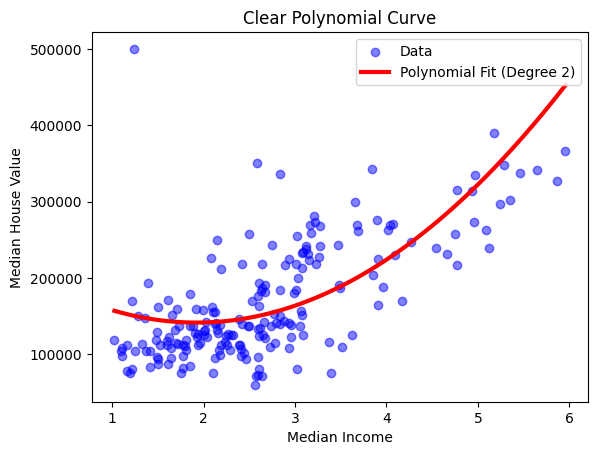

In [16]:
adam = MLPRegressor(hidden_layer_sizes=(), activation='identity', solver='adam', max_iter=5000, random_state=42)
adam.fit(X_poly, y_scaled)
results['Adam'] = mean_squared_error(y_scaled, adam.predict(X_poly))
print("Adam Error:", results['Adam'])

print("\n جميع النتائج للمقارنة ")
print(results)

plt.scatter(X, y, color='blue', alpha=0.5, label='Data')
X_grid = np.linspace(min(X), max(X), 100).reshape(-1, 1)
X_grid_scaled = scaler_X.transform(X_grid)
X_grid_poly = poly.transform(X_grid_scaled)
y_pred_scaled = adam.predict(X_grid_poly)
y_pred = scaler_y.inverse_transform(y_pred_scaled.reshape(-1, 1))

plt.plot(X_grid, y_pred, color='red', linewidth=3, label='Polynomial Fit (Degree 2)')
plt.xlabel('Median Income')
plt.ylabel('Median House Value')
plt.title('Clear Polynomial Curve')
plt.legend()
plt.show()
